# Tarea 4: Fractal de Newton en GPU

**Requisito**: `Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU T4`.

In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import time
import numpy as np
import cupy as cp
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

print(cp.cuda.runtime.getDeviceProperties(0)["name"].decode())
print(jax.devices())

Tesla T4
[CudaDevice(id=0)]


Por defecto JAX reserva el 75% de la memoria de la GPU al iniciar. La variable `XLA_PYTHON_CLIENT_PREALLOCATE` lo desactiva para que CuPy y JAX convivan en el mismo *notebook*.

## Recursos del entorno de ejecución

Características de la máquina de Google Colab: CPU, RAM y GPU. Se guardan en `resultados/info_colab.json` para el informe.

In [2]:
import json
import platform
import pandas as pd

os.makedirs("resultados", exist_ok=True)


def info_sistema():
    info = {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "cupy": cp.__version__,
        "jax": jax.__version__,
        "sistema": platform.platform(),
        "cpu_nucleos_logicos": os.cpu_count(),
    }
    try:
        import psutil
        info["cpu_nucleos_fisicos"] = psutil.cpu_count(logical=False)
        info["ram_total_GB"] = round(psutil.virtual_memory().total / 1024**3, 2)
    except ImportError:
        pass
    try:
        with open("/proc/cpuinfo") as f:
            modelos = [l.split(":", 1)[1].strip() for l in f if l.startswith("model name")]
        info["cpu_modelo"] = modelos[0]
    except (OSError, IndexError):
        info["cpu_modelo"] = platform.processor()
    props = cp.cuda.runtime.getDeviceProperties(0)
    info["gpu_modelo"] = props["name"].decode()
    info["gpu_memoria_GB"] = round(props["totalGlobalMem"] / 1024**3, 2)
    info["gpu_SMs"] = props["multiProcessorCount"]
    info["gpu_compute_capability"] = f'{props["major"]}.{props["minor"]}'
    info["gpu_warp_size"] = props["warpSize"]
    info["gpu_max_threads_por_bloque"] = props["maxThreadsPerBlock"]
    if "clockRate" in props:
        info["gpu_clock_MHz"] = props["clockRate"] / 1000
    info["cuda_runtime"] = cp.cuda.runtime.runtimeGetVersion()
    info["cuda_driver"] = cp.cuda.runtime.driverGetVersion()
    info["jax_devices"] = [str(d) for d in jax.devices()]
    return info


info_colab = info_sistema()
for k, v in info_colab.items():
    print(f"{k:28s} {v}")
with open("resultados/info_colab.json", "w") as f:
    json.dump(info_colab, f, indent=2)

python                       3.13.16
numpy                        2.4.6
cupy                         14.0.1
jax                          0.11.1
sistema                      Linux-6.6.159+-x86_64-with-glibc2.39
cpu_nucleos_logicos          2
cpu_nucleos_fisicos          1
ram_total_GB                 12.67
cpu_modelo                   Intel(R) Xeon(R) CPU @ 2.00GHz
gpu_modelo                   Tesla T4
gpu_memoria_GB               14.56
gpu_SMs                      40
gpu_compute_capability       7.5
gpu_warp_size                32
gpu_max_threads_por_bloque   1024
gpu_clock_MHz                1590.0
cuda_runtime                 13000
cuda_driver                  13000
jax_devices                  ['cuda:0']


In [3]:
!nvidia-smi
!lscpu | head -n 20
!free -h

Wed Nov 25 21:49:10 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P0             28W /   70W |     107MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Código base en NumPy

In [4]:
MAX_ITER = 100
TOL = 1e-6
ROOTS = np.array([1.0, np.exp(2j * np.pi / 3), np.exp(4j * np.pi / 3)], dtype=np.complex64)

REGIONS = {
    "clasica": (-2.0, 2.0, -2.0, 2.0),
    "frontera_central": (-0.3, 0.3, -0.3, 0.3),
    "frontera_lateral": (0.3, 0.9, 0.3, 0.9),
}


def grid(region, W):
    x_min, x_max, y_min, y_max = REGIONS[region]
    x = np.linspace(x_min, x_max, W, dtype=np.float32)
    y = np.linspace(y_min, y_max, W, dtype=np.float32)
    return (x[None, :] + 1j * y[:, None]).astype(np.complex64)


def newton_numpy(z0):
    z = z0.copy()
    count = np.zeros(z.shape, dtype=np.int32)
    active = np.ones(z.shape, dtype=bool)
    for _ in range(MAX_ITER):
        z_new = z[active] - (z[active] ** 3 - 1) / (3 * z[active] ** 2)
        converged = np.abs(z_new - z[active]) < TOL
        z[active] = z_new
        count[active] += 1
        active[active] = ~converged
        if not active.any():
            break
    root_idx = np.full(z.shape, -1, dtype=np.int32)
    for i, r in enumerate(ROOTS):
        root_idx[np.abs(z - r) < 1e-3] = i
    return root_idx, count


def graficar(root_idx, count, region):
    colors = np.array([[1.0, 0.2, 0.2], [0.2, 1.0, 0.2], [0.2, 0.2, 1.0]])
    shade = 1 - 0.85 * np.clip(count / 30, 0, 1)
    img = np.zeros(root_idx.shape + (3,))
    for i, color in enumerate(colors):
        mask = root_idx == i
        img[mask] = color * shade[mask, None]
    plt.figure(figsize=(6, 6))
    plt.imshow(img, origin="lower", extent=REGIONS[region])
    plt.title(region)
    plt.xlabel("Re(z)")
    plt.ylabel("Im(z)")
    plt.show()

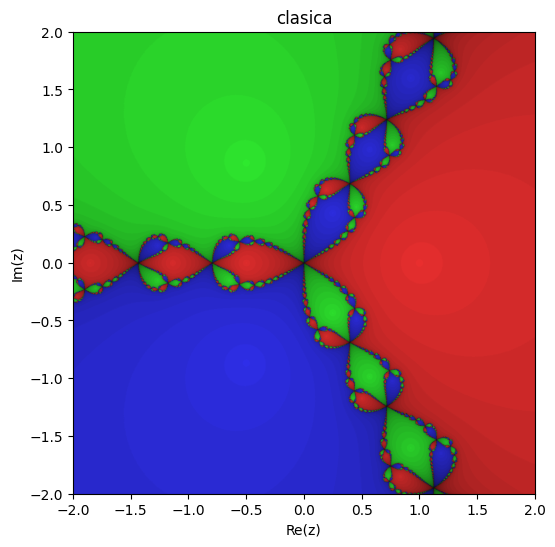

In [5]:
z0 = grid("clasica", 1024)
root_numpy, count_numpy = newton_numpy(z0)
graficar(root_numpy, count_numpy, "clasica")

## Medición de tiempos

En CuPy se usan eventos CUDA. En JAX se llama a `jax.block_until_ready()`. En ambos casos se descarta la primera llamada (*warm-up*).

In [6]:
def medir_numpy(z0):
    t = time.perf_counter()
    newton_numpy(z0)
    return time.perf_counter() - t


def medir_cupy(z0):
    newton_cupy(z0)
    inicio = cp.cuda.Event()
    fin = cp.cuda.Event()
    inicio.record()
    newton_cupy(z0)
    fin.record()
    fin.synchronize()
    return cp.cuda.get_elapsed_time(inicio, fin) / 1e3


def medir_rawkernel(z0):
    newton_rawkernel(z0)
    inicio = cp.cuda.Event()
    fin = cp.cuda.Event()
    inicio.record()
    newton_rawkernel(z0)
    fin.record()
    fin.synchronize()
    return cp.cuda.get_elapsed_time(inicio, fin) / 1e3


def medir_jax(z0):
    jax.block_until_ready(newton_jax(z0))
    t = time.perf_counter()
    jax.block_until_ready(newton_jax(z0))
    return time.perf_counter() - t


def mismatch_fraction(a, b):
    return np.mean(np.asarray(a) != np.asarray(b))

## (a) CuPy vectorizado

In [7]:
ROOTS_CP = cp.asarray(ROOTS)


def newton_cupy(z0):
    # Misma lógica de máscaras que newton_numpy, con arreglos de CuPy en la GPU.
    # z^3 se calcula como z^2 * z (NumPy también usa multiplicaciones para potencias
    # enteras complejas, mientras que el operador ** de CuPy usa exp/log).
    z = cp.asarray(z0).copy()
    count = cp.zeros(z.shape, dtype=cp.int32)
    active = cp.ones(z.shape, dtype=cp.bool_)
    for _ in range(MAX_ITER):
        za = z[active]
        za2 = za * za
        z_new = za - (za2 * za - 1) / (3 * za2)
        converged = cp.abs(z_new - za) < TOL
        z[active] = z_new
        count[active] += 1
        active[active] = ~converged
        if not active.any():          # sincroniza GPU -> CPU en cada iteración
            break
    root_idx = cp.full(z.shape, -1, dtype=cp.int32)
    for i in range(len(ROOTS)):
        root_idx[cp.abs(z - ROOTS_CP[i]) < 1e-3] = i
    return root_idx, count

z0_gpu = cp.asarray(z0)
root_cp, count_cp = newton_cupy(z0_gpu)
print("mismatch fraction:", mismatch_fraction(root_numpy, cp.asnumpy(root_cp)))
print("mismatch fraction (count):", mismatch_fraction(count_numpy, cp.asnumpy(count_cp)))
print(f"numpy: {medir_numpy(z0):.3f} s")
print(f"cupy:  {medir_cupy(z0_gpu):.4f} s")

mismatch fraction: 3.4332275390625e-05
mismatch fraction (count): 0.001132965087890625
numpy: 0.445 s
cupy:  0.1079 s


## (b) CuPy RawKernel

In [8]:
KERNEL = r'''
extern "C" __global__
void newton(const float* x, const float* y, int* root_idx, int* count,
            int n, int max_iter, float tol)
{
    int i = blockDim.x * blockIdx.x + threadIdx.x;
    if (i >= n) {
        return;
    }
    // z = zr + i*zi
    float zr = x[i];
    float zi = y[i];
    int k = 0;
    while (k < max_iter) {
        // z^2 y z^3
        float z2r = zr * zr - zi * zi;
        float z2i = 2.0f * zr * zi;
        float z3r = z2r * zr - z2i * zi;
        float z3i = z2r * zi + z2i * zr;
        // paso de Newton: (z^3 - 1) / (3 z^2)
        float nr = z3r - 1.0f;
        float ni = z3i;
        float dr = 3.0f * z2r;
        float di = 3.0f * z2i;
        float den = dr * dr + di * di;
        float pr = (nr * dr + ni * di) / den;
        float pi = (ni * dr - nr * di) / den;
        float znr = zr - pr;
        float zni = zi - pi;
        // |z_{n+1} - z_n|, igual que en la referencia. Si es NaN (z = 0) la
        // comparación es falsa y el pixel sigue iterando, como en NumPy.
        float dif = hypotf(znr - zr, zni - zi);
        zr = znr;
        zi = zni;
        k++;
        if (dif < tol) {
            break;   // este thread sale del loop en cuanto su pixel converge
        }
    }
    // raíz más cercana (a menos de 1e-3); -1 si no está cerca de ninguna
    const float rr[3] = {1.0f, -0.5f, -0.5f};
    const float ri[3] = {0.0f, 0.86602540378f, -0.86602540378f};
    int idx = -1;
    for (int r = 0; r < 3; r++) {
        if (hypotf(zr - rr[r], zi - ri[r]) < 1e-3f) {
            idx = r;
        }
    }
    root_idx[i] = idx;
    count[i] = k;
}
'''
newton_kernel = cp.RawKernel(KERNEL, "newton")


def newton_rawkernel(z0):
    x = cp.ascontiguousarray(z0.real).ravel()
    y = cp.ascontiguousarray(z0.imag).ravel()
    n = x.size
    root_idx = cp.empty(n, dtype=cp.int32)
    count = cp.empty(n, dtype=cp.int32)
    threads = 256
    blocks = (n + threads - 1) // threads
    newton_kernel((blocks,), (threads,),
                  (x, y, root_idx, count, np.int32(n), np.int32(MAX_ITER), np.float32(TOL)))
    return root_idx.reshape(z0.shape), count.reshape(z0.shape)


root_rk, count_rk = newton_rawkernel(z0_gpu)
print("mismatch fraction:", mismatch_fraction(root_numpy, cp.asnumpy(root_rk)))
print("mismatch fraction (count):", mismatch_fraction(count_numpy, cp.asnumpy(count_rk)))
print(f"rawkernel: {medir_rawkernel(z0_gpu):.4f} s")

mismatch fraction: 3.24249267578125e-05
mismatch fraction (count): 0.0011463165283203125
rawkernel: 0.0004 s


## (c) JAX

In [9]:
ROOTS_JAX = jnp.asarray(ROOTS)


def pixel(z0):
    # Estado del loop: (z actual, número de iteraciones, si el pixel sigue iterando)
    def cond(estado):
        z, k, activo = estado
        return activo & (k < MAX_ITER)

    def body(estado):
        z, k, activo = estado
        z2 = z * z
        z_new = z - (z2 * z - 1) / (3 * z2)
        # ~(d < TOL) en vez de (d >= TOL) para que un NaN siga iterando, como en la referencia
        activo = ~(jnp.abs(z_new - z) < TOL)
        return z_new, k + 1, activo

    z, k, _ = jax.lax.while_loop(cond, body, (z0, jnp.int32(0), jnp.bool_(True)))
    cerca = jnp.abs(z - ROOTS_JAX) < 1e-3
    root_idx = jnp.where(jnp.any(cerca), jnp.argmax(cerca), -1).astype(jnp.int32)
    return root_idx, k


@jax.jit
def newton_jax(z0):
    # vmap anidado: el interno recorre las columnas y el externo las filas
    return jax.vmap(jax.vmap(pixel))(z0)

z0_jax = jnp.asarray(z0)
root_jx, count_jx = newton_jax(z0_jax)
print("mismatch fraction:", mismatch_fraction(root_numpy, root_jx))
print("mismatch fraction (count):", mismatch_fraction(count_numpy, count_jx))
print(f"jax: {medir_jax(z0_jax):.4f} s")

mismatch fraction: 1.9073486328125e-05
mismatch fraction (count): 0.000274658203125
jax: 0.0088 s


## (d)

In [10]:
Ws = [1024, 2048, 4096, 8192]
REPS = 3   # cada medición se repite REPS veces (cada una con su warm-up); se reporta la mediana

plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13,
    "legend.fontsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
})

### Imágenes de las tres regiones con $W = 1024$

Se calculan con la versión RawKernel y se verifican contra la referencia de NumPy.

clasica            mismatch root_idx: 3.24e-05  mismatch count: 1.15e-03


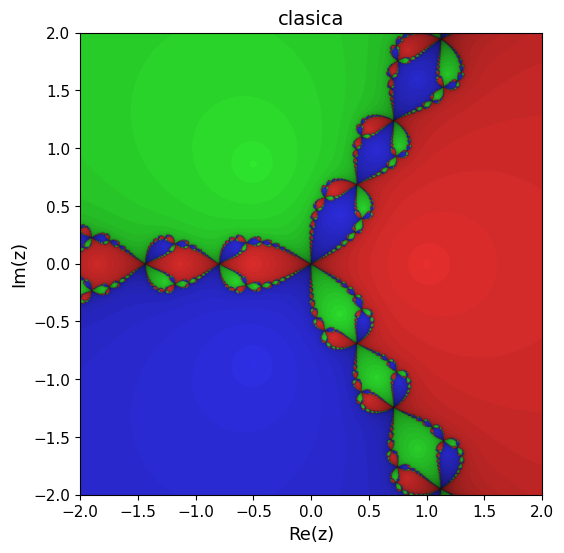

frontera_central   mismatch root_idx: 4.58e-05  mismatch count: 1.36e-03


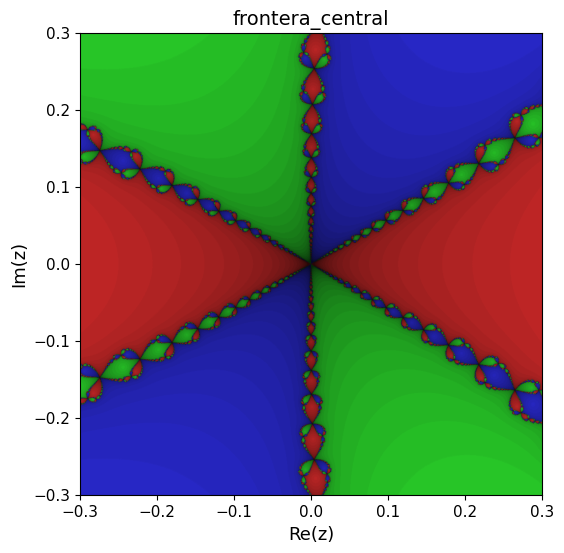

frontera_lateral   mismatch root_idx: 6.87e-05  mismatch count: 1.24e-03


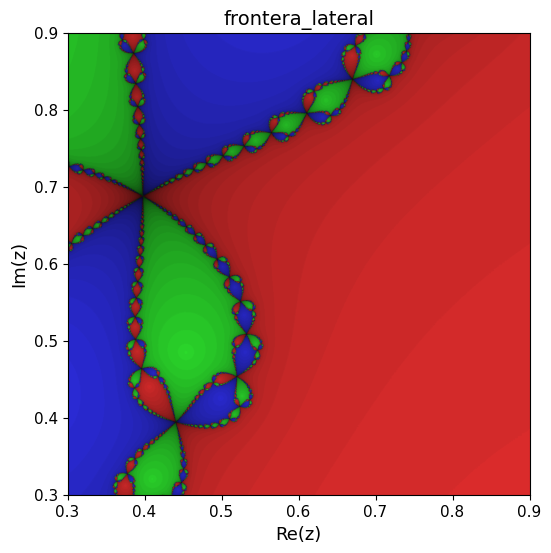

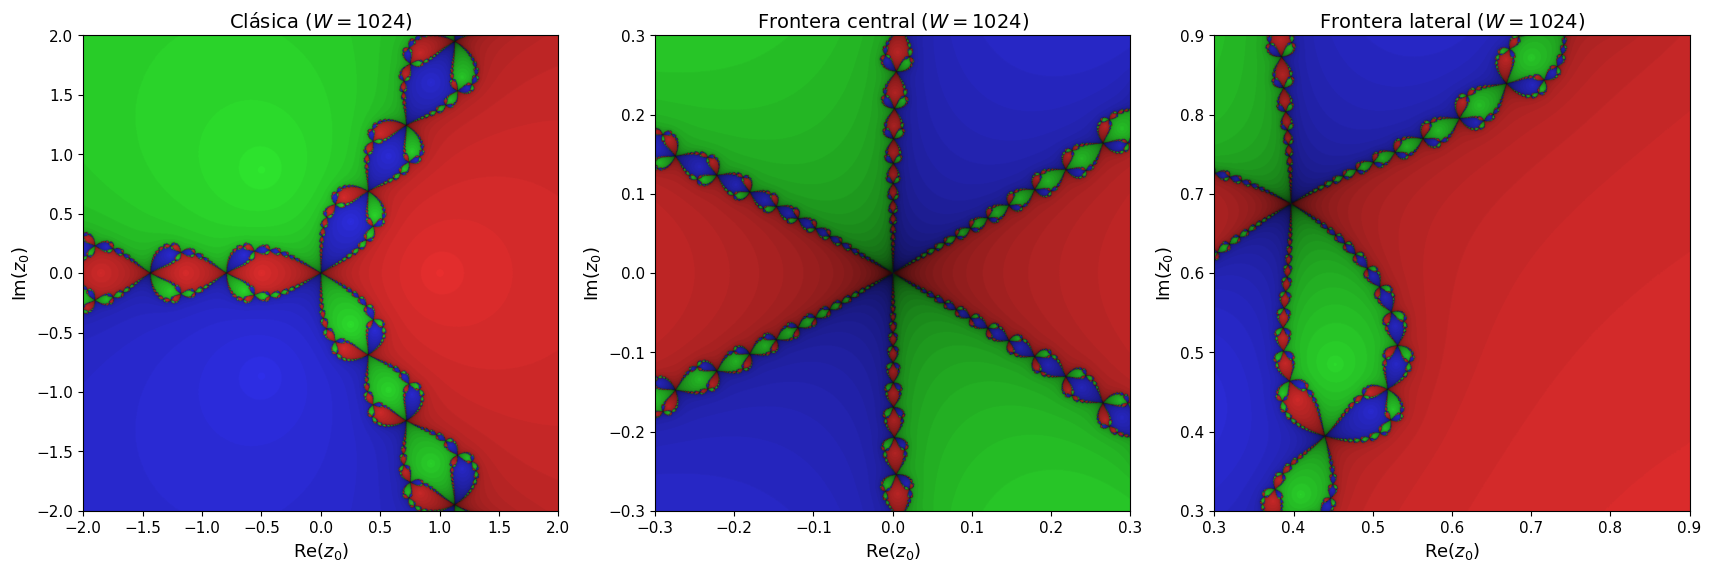

In [11]:
def imagen(root_idx, count):
    # misma coloración que graficar
    colors = np.array([[1.0, 0.2, 0.2], [0.2, 1.0, 0.2], [0.2, 0.2, 1.0]])
    shade = 1 - 0.85 * np.clip(count / 30, 0, 1)
    img = np.zeros(root_idx.shape + (3,))
    for i, color in enumerate(colors):
        mask = root_idx == i
        img[mask] = color * shade[mask, None]
    return img


TITULOS = {"clasica": "Clásica", "frontera_central": "Frontera central",
           "frontera_lateral": "Frontera lateral"}
res_1024 = {}
for region in REGIONS:
    z0_r = grid(region, 1024)
    r, c = newton_rawkernel(cp.asarray(z0_r))
    r, c = cp.asnumpy(r), cp.asnumpy(c)
    r_ref, c_ref = newton_numpy(z0_r)
    print(f"{region:18s} mismatch root_idx: {mismatch_fraction(r_ref, r):.2e}  "
          f"mismatch count: {mismatch_fraction(c_ref, c):.2e}")
    res_1024[region] = (r, c)
    graficar(r, c, region)

# Figura combinada para el informe
fig, axs = plt.subplots(1, 3, figsize=(17, 6), constrained_layout=True)
for ax, region in zip(axs, REGIONS):
    r, c = res_1024[region]
    ax.imshow(imagen(r, c), origin="lower", extent=REGIONS[region])
    ax.set_title(f"{TITULOS[region]} ($W=1024$)")
    ax.set_xlabel("Re($z_0$)")
    ax.set_ylabel("Im($z_0$)")
fig.savefig("resultados/fractales_W1024.png", dpi=200)
fig.savefig("resultados/fractales_W1024.pdf")
plt.show()

### Medición de tiempos en GPU

Para cada región y cada $W$ se mide CuPy vectorizado, CuPy RawKernel y JAX. Cada versión se verifica:

- para $W = 1024$, contra la referencia de NumPy (que además se mide una vez en la CPU de Colab);
- para $W > 1024$, contra CuPy vectorizado, que replica la lógica de NumPy, porque NumPy es muy lento con esos tamaños.

También se guardan estadísticas de las iteraciones por pixel (`count`) para analizar la divergencia en (e).

In [12]:
def estadisticas_iteraciones(count, root_idx):
    c = np.asarray(count).ravel().astype(np.int64)
    # newton_rawkernel usa bloques 1D de 256 threads sobre la grid aplanada por filas:
    # un warp son 32 pixeles consecutivos de una misma fila.
    max_warp = c.reshape(-1, 32).max(axis=1)
    return {
        "iter_media": c.mean(),
        "iter_desv": c.std(),
        "iter_max": int(c.max()),
        "frac_no_converge": float(np.mean(np.asarray(root_idx) == -1)),
        "iter_max_warp_media": max_warp.mean(),
        # trabajo útil / trabajo hecho por los warps (1 = sin divergencia)
        "eficiencia_warp": c.sum() / (32 * max_warp.sum()),
        # vmap + while_loop: todos los pixeles iteran hasta el máximo global
        "eficiencia_jax": c.mean() / c.max(),
    }


VERSIONES = [
    ("CuPy vectorizado", medir_cupy, "gpu"),
    ("CuPy RawKernel", medir_rawkernel, "gpu"),
    ("JAX", medir_jax, "jax"),
]

filas_tiempos, filas_stats = [], []
for region in REGIONS:
    for W in Ws:
        z0_cpu = grid(region, W)
        entradas = {"gpu": cp.asarray(z0_cpu), "jax": jnp.asarray(z0_cpu)}

        r_cp, c_cp = (cp.asnumpy(a) for a in newton_cupy(entradas["gpu"]))
        r_rk, c_rk = (cp.asnumpy(a) for a in newton_rawkernel(entradas["gpu"]))
        r_jx, c_jx = (np.asarray(a) for a in newton_jax(entradas["jax"]))
        salidas = {"CuPy vectorizado": (r_cp, c_cp), "CuPy RawKernel": (r_rk, c_rk), "JAX": (r_jx, c_jx)}

        if W == 1024:
            t = time.perf_counter()
            r_ref, c_ref = newton_numpy(z0_cpu)
            t_np = time.perf_counter() - t
            ref = "NumPy"
            filas_tiempos.append(dict(region=region, W=W, version="NumPy (CPU Colab)", t_mediana=t_np,
                                      t_min=t_np, t_max=t_np, referencia="-", mismatch_root=0.0, mismatch_count=0.0))
        else:
            r_ref, c_ref, ref = r_cp, c_cp, "CuPy vectorizado"

        for nombre, medir, tipo in VERSIONES:
            ts = [medir(entradas[tipo]) for _ in range(REPS)]
            r, c = salidas[nombre]
            filas_tiempos.append(dict(
                region=region, W=W, version=nombre,
                t_mediana=float(np.median(ts)), t_min=float(min(ts)), t_max=float(max(ts)),
                referencia=ref, mismatch_root=mismatch_fraction(r_ref, r), mismatch_count=mismatch_fraction(c_ref, c)))
            f = filas_tiempos[-1]
            print(f"{region:18s} W={W:5d} {nombre:17s} {f['t_mediana']:9.4f} s   "
                  f"mismatch vs {ref}: {f['mismatch_root']:.1e}")

        filas_stats.append(dict(region=region, W=W, **estadisticas_iteraciones(c_rk, r_rk)))

        del entradas, salidas, r_cp, c_cp, r_rk, c_rk, r_jx, c_jx
        cp.get_default_memory_pool().free_all_blocks()

tiempos = pd.DataFrame(filas_tiempos)
stats = pd.DataFrame(filas_stats)
tiempos.to_csv("resultados/tiempos_gpu.csv", index=False)
stats.to_csv("resultados/estadisticas_iteraciones.csv", index=False)

clasica            W= 1024 CuPy vectorizado     0.0889 s   mismatch vs NumPy: 3.4e-05
clasica            W= 1024 CuPy RawKernel       0.0003 s   mismatch vs NumPy: 3.2e-05
clasica            W= 1024 JAX                  0.0088 s   mismatch vs NumPy: 1.9e-05
clasica            W= 2048 CuPy vectorizado     0.3031 s   mismatch vs CuPy vectorizado: 0.0e+00
clasica            W= 2048 CuPy RawKernel       0.0010 s   mismatch vs CuPy vectorizado: 3.2e-05
clasica            W= 2048 JAX                  0.0338 s   mismatch vs CuPy vectorizado: 3.8e-05
clasica            W= 4096 CuPy vectorizado     1.1098 s   mismatch vs CuPy vectorizado: 0.0e+00
clasica            W= 4096 CuPy RawKernel       0.0040 s   mismatch vs CuPy vectorizado: 2.9e-05
clasica            W= 4096 JAX                  0.1333 s   mismatch vs CuPy vectorizado: 3.0e-05
clasica            W= 8192 CuPy vectorizado     5.8245 s   mismatch vs CuPy vectorizado: 0.0e+00
clasica            W= 8192 CuPy RawKernel       0.0218 s   mism

### Tabla de tiempos (mediana, en segundos) y *speedups*

In [13]:
ORDEN = ["NumPy (CPU Colab)", "CuPy vectorizado", "CuPy RawKernel", "JAX"]
tabla = (tiempos.pivot_table(index=["region", "W"], columns="version", values="t_mediana")
         .reindex(columns=ORDEN))
tabla["RawKernel vs CuPy vect."] = tabla["CuPy vectorizado"] / tabla["CuPy RawKernel"]
tabla["JAX vs CuPy vect."] = tabla["CuPy vectorizado"] / tabla["JAX"]
tabla["RawKernel vs JAX"] = tabla["JAX"] / tabla["CuPy RawKernel"]
tabla.to_csv("resultados/tabla_tiempos_gpu.csv")
try:
    with open("resultados/tabla_tiempos_gpu.tex", "w") as f:
        f.write(tabla.to_latex(float_format="%.4f", na_rep="--"))
except ImportError as e:
    print("No se pudo exportar a LaTeX:", e)
display(tabla.style.format("{:.4f}", na_rep="--"))

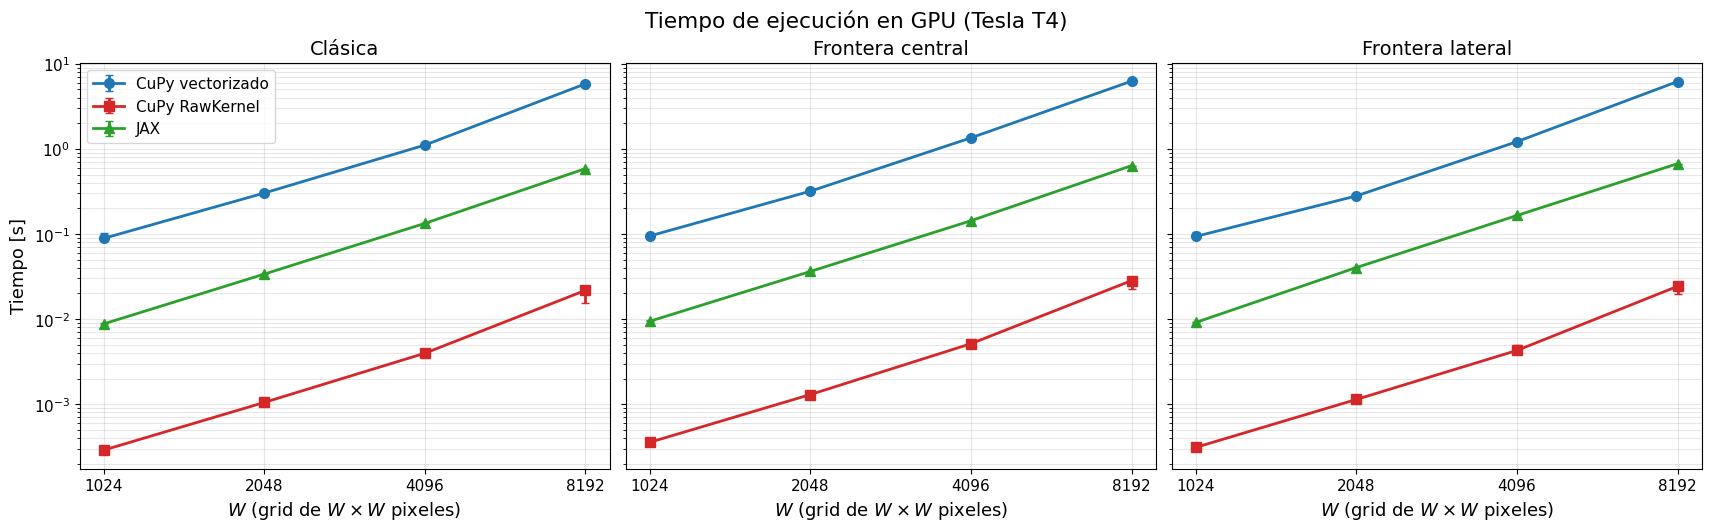

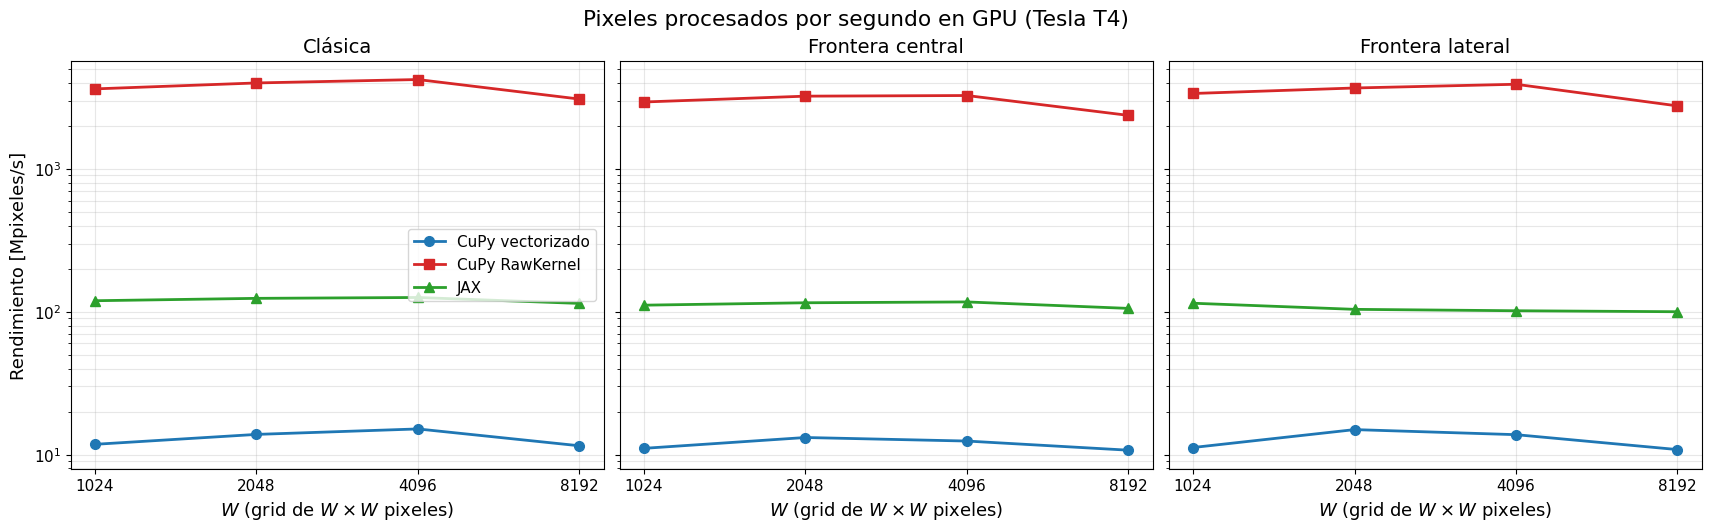

In [14]:
ESTILO = {
    "CuPy vectorizado": dict(color="#1f77b4", marker="o"),
    "CuPy RawKernel": dict(color="#d62728", marker="s"),
    "JAX": dict(color="#2ca02c", marker="^"),
}

fig, axs = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True, constrained_layout=True)
for ax, region in zip(axs, REGIONS):
    for version, estilo in ESTILO.items():
        d = tiempos[(tiempos.region == region) & (tiempos.version == version)].sort_values("W")
        ax.errorbar(d.W, d.t_mediana, yerr=[d.t_mediana - d.t_min, d.t_max - d.t_mediana],
                    label=version, capsize=3, lw=2, ms=7, **estilo)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(Ws, [str(w) for w in Ws])
    ax.set_title(TITULOS[region])
    ax.set_xlabel("$W$ (grid de $W \\times W$ pixeles)")
    ax.grid(True, which="both", alpha=0.3)
axs[0].set_ylabel("Tiempo [s]")
axs[0].legend()
fig.suptitle(f"Tiempo de ejecución en GPU ({info_colab['gpu_modelo']})")
fig.savefig("resultados/tiempos_gpu.png", dpi=200)
fig.savefig("resultados/tiempos_gpu.pdf")
plt.show()

# Rendimiento en Mpixeles/s
fig, axs = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True, constrained_layout=True)
for ax, region in zip(axs, REGIONS):
    for version, estilo in ESTILO.items():
        d = tiempos[(tiempos.region == region) & (tiempos.version == version)].sort_values("W")
        ax.plot(d.W, d.W**2 / d.t_mediana / 1e6, label=version, lw=2, ms=7, **estilo)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xticks(Ws, [str(w) for w in Ws])
    ax.set_title(TITULOS[region])
    ax.set_xlabel("$W$ (grid de $W \\times W$ pixeles)")
    ax.grid(True, which="both", alpha=0.3)
axs[0].set_ylabel("Rendimiento [Mpixeles/s]")
axs[0].legend()
fig.suptitle(f"Pixeles procesados por segundo en GPU ({info_colab['gpu_modelo']})")
fig.savefig("resultados/rendimiento_gpu.png", dpi=200)
fig.savefig("resultados/rendimiento_gpu.pdf")
plt.show()

### Comparación CPU vs GPU

Los tiempos de NumPy y JAX en un computador propio se miden con el *script* `benchmark_cpu.py`, que genera `tiempos_cpu.csv` e `info_cpu.json`. Si se sube `tiempos_cpu.csv` a la carpeta `resultados/` de Colab, la siguiente celda los compara con los tiempos en GPU.

In [15]:
ruta_cpu = "resultados/tiempos_cpu.csv"
if os.path.exists(ruta_cpu):
    tiempos_cpu = pd.read_csv(ruta_cpu)
    tiempos_cpu["version"] = tiempos_cpu["version"] + " (CPU propio)"
    gpu = tiempos[tiempos.version != "NumPy (CPU Colab)"].copy()
    gpu["version"] = gpu["version"] + " (GPU)"
    todos = pd.concat([gpu, tiempos_cpu], ignore_index=True)
    tabla_cpu_gpu = todos.pivot_table(index=["region", "W"], columns="version", values="t_mediana")
    tabla_cpu_gpu.to_csv("resultados/tabla_cpu_gpu.csv")
    display(tabla_cpu_gpu.style.format("{:.4f}", na_rep="--"))

    estilos = {**{k + " (GPU)": v for k, v in ESTILO.items()},
               "NumPy (CPU propio)": dict(color="#7f7f7f", marker="D", ls="--"),
               "JAX (CPU propio)": dict(color="#9467bd", marker="v", ls="--")}
    fig, axs = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True, constrained_layout=True)
    for ax, region in zip(axs, REGIONS):
        for version, estilo in estilos.items():
            d = todos[(todos.region == region) & (todos.version == version)].sort_values("W")
            if len(d):
                ax.plot(d.W, d.t_mediana, label=version, lw=2, ms=7, **estilo)
        ax.set_xscale("log", base=2)
        ax.set_yscale("log")
        ax.set_xticks(Ws, [str(w) for w in Ws])
        ax.set_title(TITULOS[region])
        ax.set_xlabel("$W$ (grid de $W \\times W$ pixeles)")
        ax.grid(True, which="both", alpha=0.3)
    axs[0].set_ylabel("Tiempo [s]")
    axs[0].legend(fontsize=10)
    fig.suptitle("Tiempo de ejecución: CPU propio vs GPU de Colab")
    fig.savefig("resultados/tiempos_cpu_vs_gpu.png", dpi=200)
    fig.savefig("resultados/tiempos_cpu_vs_gpu.pdf")
    plt.show()
else:
    print(f"No se encontró {ruta_cpu}; se omite la comparación CPU vs GPU en el notebook.")

No se encontró resultados/tiempos_cpu.csv; se omite la comparación CPU vs GPU en el notebook.


## (e) Datos para el análisis de divergencia

- **`eficiencia_warp`** = $\sum_p \text{count}_p \,/\, \sum_{w} 32 \cdot \max_{p \in w} \text{count}_p$. Es la fracción del trabajo de los *warps* del RawKernel que corresponde a iteraciones útiles. Vale 1 si no hay divergencia.
- **`eficiencia_jax`** = $\overline{\text{count}} / \max \text{count}$. Con `vmap` de un `while_loop`, el *loop* se ejecuta hasta que termina el último pixel de toda la *grid*, así que cada pixel ejecuta $\max \text{count}$ iteraciones.

In [16]:
cols = ["iter_media", "iter_desv", "iter_max", "frac_no_converge", "iter_max_warp_media",
        "eficiencia_warp", "eficiencia_jax"]
tabla_stats = stats.set_index(["region", "W"])[cols]
try:
    with open("resultados/estadisticas_iteraciones.tex", "w") as f:
        f.write(tabla_stats.to_latex(float_format="%.3f"))
except ImportError as e:
    print("No se pudo exportar a LaTeX:", e)
display(tabla_stats.style.format("{:.3f}"))

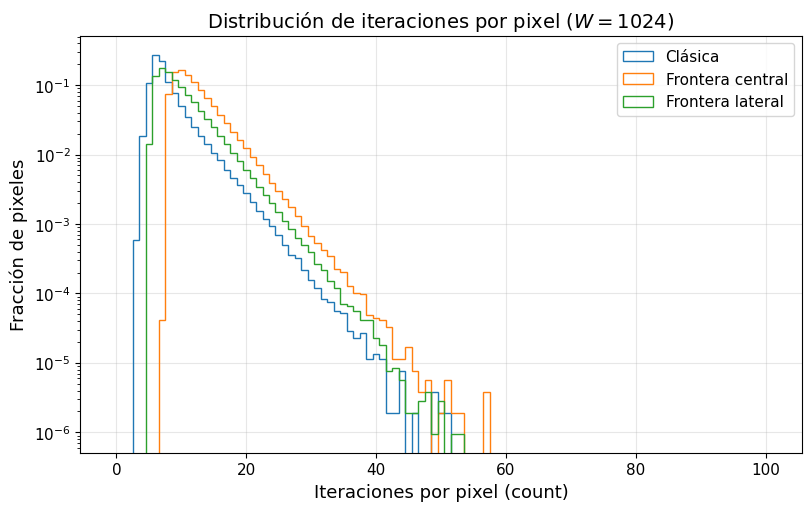

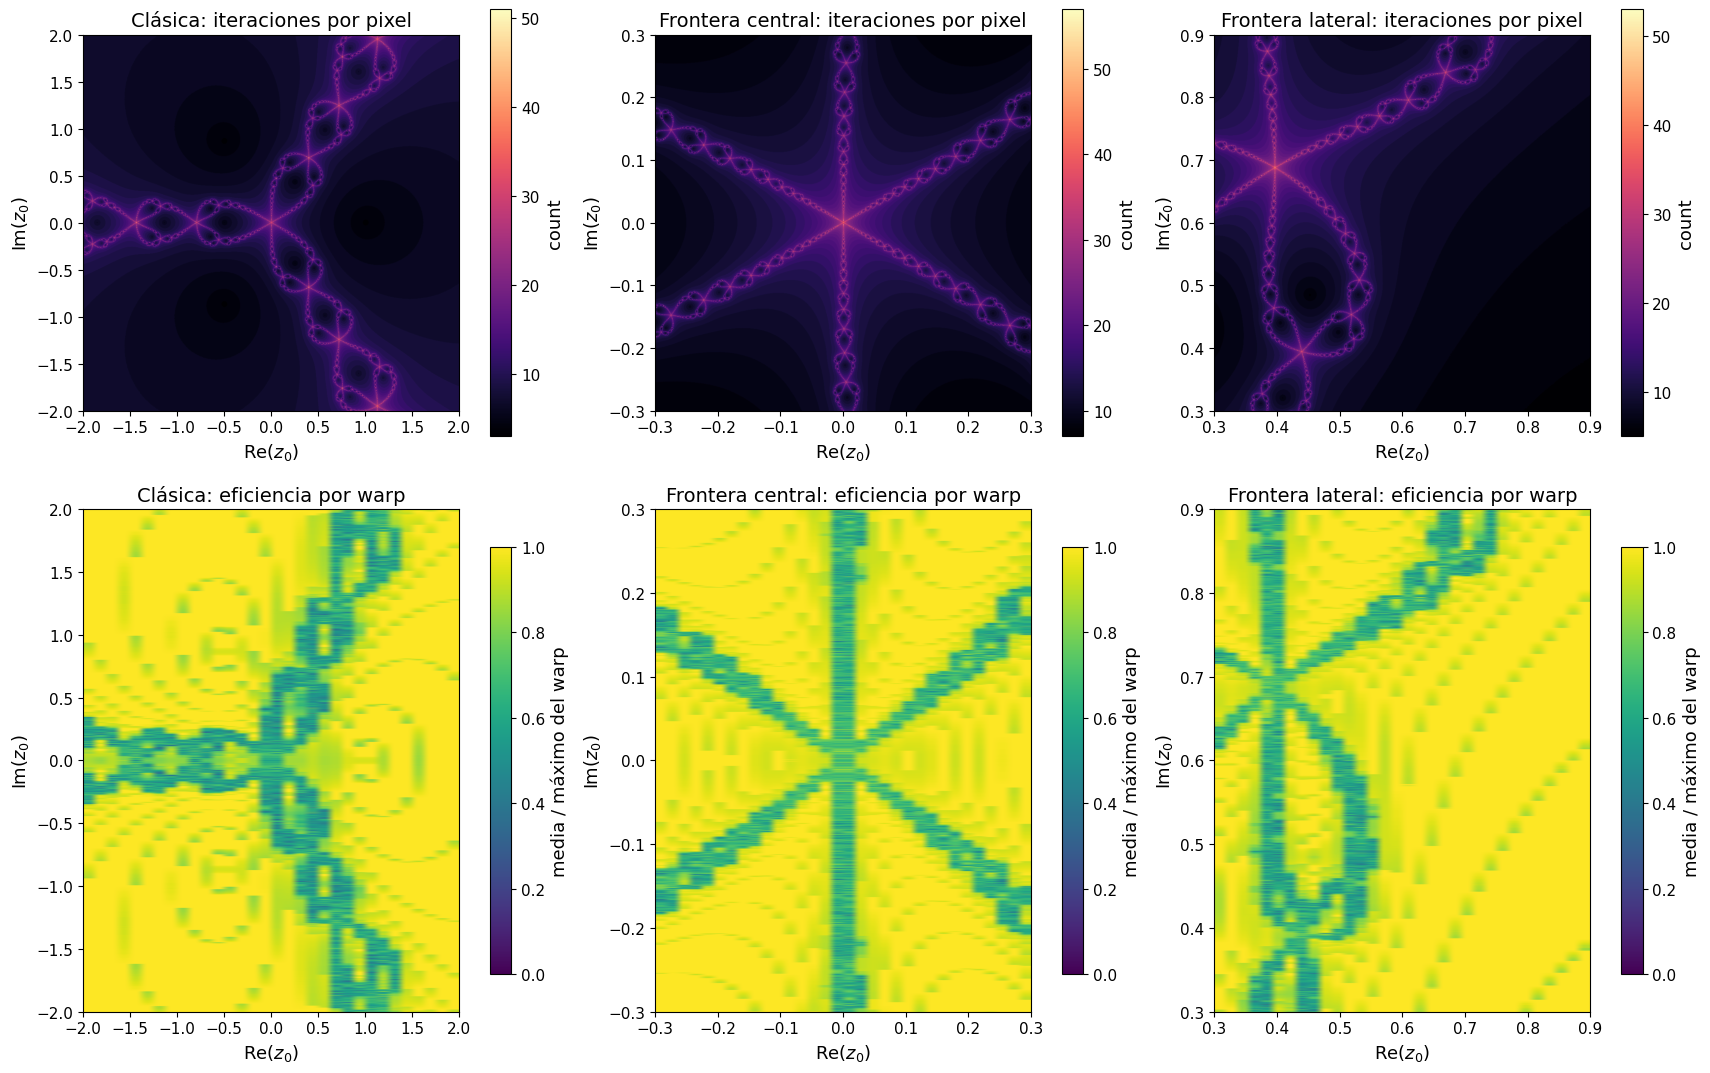

In [17]:
# Histograma de iteraciones por pixel (W = 1024)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
bins = np.arange(0, MAX_ITER + 2) - 0.5
for region in REGIONS:
    ax.hist(res_1024[region][1].ravel(), bins=bins, histtype="step", lw=2,
            density=True, label=TITULOS[region])
ax.set_xlabel("Iteraciones por pixel (count)")
ax.set_ylabel("Fracción de pixeles")
ax.set_yscale("log")
ax.set_title("Distribución de iteraciones por pixel ($W=1024$)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.savefig("resultados/histograma_iteraciones.png", dpi=200)
fig.savefig("resultados/histograma_iteraciones.pdf")
plt.show()

# Mapas de iteraciones y de eficiencia por warp (W = 1024)
fig, axs = plt.subplots(2, 3, figsize=(17, 11), constrained_layout=True)
for j, region in enumerate(REGIONS):
    c = res_1024[region][1]
    im = axs[0, j].imshow(c, origin="lower", extent=REGIONS[region], cmap="magma")
    axs[0, j].set_title(f"{TITULOS[region]}: iteraciones por pixel")
    fig.colorbar(im, ax=axs[0, j], label="count", shrink=0.85)
    warps = c.reshape(c.shape[0], -1, 32)
    efic = warps.mean(axis=2) / warps.max(axis=2)
    im = axs[1, j].imshow(efic, origin="lower", extent=REGIONS[region], cmap="viridis",
                          vmin=0, vmax=1, aspect="auto")
    axs[1, j].set_title(f"{TITULOS[region]}: eficiencia por warp")
    fig.colorbar(im, ax=axs[1, j], label="media / máximo del warp", shrink=0.85)
    for i in range(2):
        axs[i, j].set_xlabel("Re($z_0$)")
        axs[i, j].set_ylabel("Im($z_0$)")
fig.savefig("resultados/divergencia_W1024.png", dpi=200)
fig.savefig("resultados/divergencia_W1024.pdf")
plt.show()

## Descargar resultados

Se comprime la carpeta `resultados/` (CSV, tablas `.tex`, figuras `.png`/`.pdf` e información del entorno).

In [18]:
import shutil
shutil.make_archive("resultados_tarea04", "zip", "resultados")
try:
    from google.colab import files
    files.download("resultados_tarea04.zip")
except ImportError:
    print("resultados_tarea04.zip creado")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>